# Visualize Token Graphs for Additional Structured Numerical Inputs

This Visualize notebook loads the cache produced by `Generate-token-graphs-additional-numerical-inputs.ipynb` and generates the combined last-layer attention-induced token-graph and state-trajectory figure for **Attention-Induced Token Graphs for Additional Structured Numerical Inputs** in the appendix. This figure illustrates qualitative graph-organization patterns beyond the main dynamical-system trajectories.

The graph grid shows five structured numerical input families with Llama-3.2-3B at 10%, 30%, 50%, 70%, and 90% of a 1,000-token reference context. Node positions use attention-weighted Fruchterman–Reingold layouts; edge thickness and opacity encode attention weight, and only edges above $2.5/N$ are displayed, where $N$ is the number of graph nodes. Node colors encode the leading three uncentered hidden-state SVD coordinates, with channel ranges shared across contexts within each input family. Circles mark numeric tokens and triangles mark separator tokens. Each original input trajectory appears above its five graph snapshots in the combined figure.


Set imports, retained inputs, relative data and figure paths, and figure styles.


In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Reference context and relative cache and figure paths
REFERENCE_CONTEXT_TOKENS = 1000
CONTEXT_FRACS = (0.10, 0.30, 0.50, 0.70, 0.90)
PROCESSED_DATA_DIR = Path('processed_last_layer_additional_inputs_data')
FIGURE_OUTPUT_DIR = Path('figure')

# Input order and display labels
DATA_ORDER = [
    'Gaussian switch @50%',
    'Gaussian switches @35%,65%',
    'sin(x)',
    'Random walk',
    'Random walk with drift',
]

TITLE_OVERRIDES = {
    'Gaussian switch @50%': 'Gaussian sequence with one switch at 50%',
    'Gaussian switches @35%,65%': 'Gaussian sequence with switches at 35% and 65%',
    'sin(x)': 'Sine wave sequence',
}

# Required arrays in each processed archive
GRAPH_DATA_ARRAY_KEYS = (
    'Wbar',
    'layout_positions',
    'svd_projection_coords',
    'is_delimiter',
    'state_values',
)

# Attention-graph style
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_EDGE_STYLE_BINS = 20
RGB_GRAPH_X_MARGIN = 0.01
RGB_GRAPH_Y_MARGIN = 0.06
DISPLAY_DPI = 150
FIGURE_DPI = 300
SAVEFIG_PAD_INCHES = 0.03

# Typography and token markers
PANEL_TITLE_FONT_SIZE = 10.0
AXIS_LABEL_FONT_SIZE = 10.0
Y_AXIS_LABEL_FONT_SIZE = AXIS_LABEL_FONT_SIZE
TICK_LABEL_FONT_SIZE = AXIS_LABEL_FONT_SIZE
AXIS_LABEL_PAD = 1.5
PANEL_TITLE_PAD = 4.0
GRAPH_STATE_MARKER_SIZE = 18.0
GRAPH_DELIMITER_MARKER_SIZE = 24.0
GRAPH_STATE_MARKER_SIZE_FLOOR = 8.0
GRAPH_DELIMITER_MARKER_SIZE_FLOOR = 10.0
GRAPH_MARKER_SCALE_FLOOR = 0.22
GRAPH_MARKER_SCALE_EXPONENT = 0.60
ADDITIONAL_INPUTS_NODE_SIZE_SCALE = 0.55

# State trajectories and context-progress markers
TRAJECTORY_LINE_COLOR = '#D6D6D6'
TRAJECTORY_POINT_COLOR = '#4A4A4A'
TRAJECTORY_AXIS_LABEL_FONT_SIZE = 10.8
TRAJECTORY_TICK_LABEL_FONT_SIZE = 10.5
TRAJECTORY_CONTEXT_LABEL_FONT_SIZE = 8.4
TRAJECTORY_Y_LIMITS = (0.0, 1000.0)
TRAJECTORY_Y_TICKS = (100, 500, 900)
TRAJECTORY_Y_LIMITS_BY_DATA_NAME = {'sin(x)': None}
TRAJECTORY_Y_TICKS_BY_DATA_NAME = {'sin(x)': (-1.0, 1.0)}
TRAJECTORY_ADAPTIVE_Y_PAD_FRAC = 0.08
PROGRESS_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
PROGRESS_COLOR_MAP = {float(frac): PROGRESS_COLORS[i] for i, frac in enumerate(CONTEXT_FRACS)}

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = FIGURE_DPI

Define context labels and trajectory-axis limits, then load and validate the graph archives.


In [2]:
def panel_title(data_name):
    return TITLE_OVERRIDES.get(str(data_name), str(data_name))


def context_fraction_label(frac):
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def context_percent_label(frac):
    return f'{int(round(100 * float(frac)))}%'


def safe_data_stem(data_name, frac=CONTEXT_FRACS[-1]):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRACS[-1], data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


def context_state_count_from_frac(frac, total_states):
    frac_use = float(frac)
    if frac_use >= 1.0:
        return int(total_states)
    ctx_len = max(1, int(round(frac_use * (int(total_states) - 1))))
    return min(int(total_states), ctx_len)


def context_state_index(frac, total_states):
    return max(0, context_state_count_from_frac(frac, total_states=total_states) - 1)


def trajectory_display_state_values(data_name, state_values):
    state_values = np.asarray(state_values, dtype=float)
    return state_values


def trajectory_y_limits_and_ticks(data_name):
    data_name = str(data_name)
    return (
        TRAJECTORY_Y_LIMITS_BY_DATA_NAME.get(data_name, TRAJECTORY_Y_LIMITS),
        TRAJECTORY_Y_TICKS_BY_DATA_NAME.get(data_name, TRAJECTORY_Y_TICKS),
    )


def adaptive_y_limits(values, pad_frac=TRAJECTORY_ADAPTIVE_Y_PAD_FRAC):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return TRAJECTORY_Y_LIMITS
    y_min = float(np.min(finite))
    y_max = float(np.max(finite))
    span = max(y_max - y_min, 1e-9)
    pad = span * float(pad_frac)
    return y_min - pad, y_max + pad


def validate_processed_graph_payload(payload, path=None):
    missing = [key for key in GRAPH_DATA_ARRAY_KEYS if key not in payload]
    if missing:
        raise KeyError(f'{path or "archive"} is missing required arrays: {missing}')

    Wbar = np.asarray(payload['Wbar'])
    if Wbar.ndim != 2 or Wbar.shape[0] != Wbar.shape[1]:
        raise ValueError(f'{path or "archive"} has non-square Wbar with shape {Wbar.shape}')
    n_nodes = int(Wbar.shape[0])

    # Every graph-derived array must use the same token-node order and count.
    expected_shapes = {
        'layout_positions': (n_nodes, 2),
        'svd_projection_coords': (n_nodes, 3),
        'is_delimiter': (n_nodes,),
    }
    for key, shape in expected_shapes.items():
        actual = np.asarray(payload[key]).shape
        if actual != shape:
            raise ValueError(f'{path or "archive"} has {key} shape {actual}, expected {shape}')

    state_values = np.asarray(payload['state_values'])
    if state_values.ndim != 1 or state_values.size == 0:
        raise ValueError(f'{path or "archive"} has invalid state_values shape {state_values.shape}')


def load_processed_graph_data(data_name, frac, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}
    validate_processed_graph_payload(processed_data, path=path)
    return processed_data


def check_processed_graph_data(data_names=DATA_ORDER, fracs=CONTEXT_FRACS, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    line_sep = chr(10)
    for frac in fracs:
        for data_name in data_names:
            path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
            if not path.exists():
                missing.append(path)
                continue
            try:
                load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
            except (OSError, KeyError, ValueError) as exc:
                invalid.append((path, exc))
    if missing:
        raise FileNotFoundError('Missing processed graph data:' + line_sep + line_sep.join(str(path) for path in missing))
    if invalid:
        details = line_sep.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:' + line_sep + details)

Prepare shared color and edge scales, then draw token graphs and state trajectories.


In [3]:
def minmax_scale_rgb_channels(coords, channel_limits=None, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')
    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb
    if channel_limits is None:
        channel_min = channel_max = None
    else:
        limit_min, limit_max = (np.asarray(value, dtype=float).ravel() for value in channel_limits)
        channel_min = np.full(3, np.nan, dtype=float)
        channel_max = np.full(3, np.nan, dtype=float)
        channel_min[:min(3, limit_min.size)] = limit_min[:3]
        channel_max[:min(3, limit_max.size)] = limit_max[:3]
    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        if channel_limits is None:
            cmin = float(np.min(col[finite]))
            cmax = float(np.max(col[finite]))
        else:
            cmin = float(channel_min[k])
            cmax = float(channel_max[k])
        if (not np.isfinite(cmin)) or (not np.isfinite(cmax)) or (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)
    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


def graph_marker_scale(frac):
    frac_use = max(min(float(frac), 1.0), 0.10)
    return float(np.clip((0.10 / frac_use) ** GRAPH_MARKER_SCALE_EXPONENT, GRAPH_MARKER_SCALE_FLOOR, 1.0))


def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)


def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')
    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    # Draw each undirected edge once, excluding self-loops.
    iu = np.triu_indices(n, k=1)
    w = W[iu]
    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]
    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx
    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


# Use one edge-weight scale across all displayed inputs and contexts
def edge_weight_limits_from_payload_grid(payload_grid):
    weights = []
    for payloads_by_frac in payload_grid.values():
        for payload in payloads_by_frac.values():
            _, _, w_edges = select_top_edges(
                payload['Wbar'],
                max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
                threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
            )
            if w_edges.size:
                weights.append(w_edges)
    if not weights:
        return (0.0, 0.0)
    weights = np.concatenate(weights)
    return float(np.min(weights)), float(np.max(weights))


def rgb_channel_limits_from_payloads(payloads):
    channel_values = [[] for _ in range(3)]
    for payload in payloads:
        coords = np.asarray(payload['svd_projection_coords'], dtype=float)
        if coords.ndim == 1:
            coords = coords[:, None]
        if coords.ndim != 2:
            continue
        for k in range(min(3, coords.shape[1])):
            col = np.asarray(coords[:, k], dtype=float)
            finite = np.isfinite(col)
            if np.any(finite):
                channel_values[k].append(col[finite])
    channel_min = np.full(3, np.nan, dtype=float)
    channel_max = np.full(3, np.nan, dtype=float)
    for k, values in enumerate(channel_values):
        if not values:
            continue
        values = np.concatenate(values)
        channel_min[k] = float(np.min(values))
        channel_max[k] = float(np.max(values))
    return channel_min, channel_max


# Share RGB channel ranges across contexts within each input family
def rgb_channel_limits_by_data_name(payload_grid, data_names=None, fracs=None):
    if data_names is None:
        data_names = payload_grid.keys()
    limits = {}
    for data_name in data_names:
        payloads_by_frac = payload_grid[data_name]
        if fracs is None:
            payloads = payloads_by_frac.values()
        else:
            payloads = [payloads_by_frac[float(frac)] for frac in fracs]
        limits[data_name] = rgb_channel_limits_from_payloads(payloads)
    return limits


def set_tight_equal_graph_limits(ax, x, y, pad_frac=None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x) & np.isfinite(y)
    if not np.any(finite):
        return
    x = x[finite]
    y = y[finite]
    x_min, x_max = float(np.min(x)), float(np.max(x))
    y_min, y_max = float(np.min(y)), float(np.max(y))
    span = max(x_max - x_min, y_max - y_min, 1e-9)
    pad = span * (max(RGB_GRAPH_X_MARGIN, RGB_GRAPH_Y_MARGIN) if pad_frac is None else float(pad_frac))
    half_span = 0.5 * span + pad
    x_mid = 0.5 * (x_min + x_max)
    y_mid = 0.5 * (y_min + y_max)
    ax.set_xlim(x_mid - half_span, x_mid + half_span)
    ax.set_ylim(y_mid - half_span, y_mid + half_span)


def add_graph_progress_indicator(ax, frac):
    color = PROGRESS_COLOR_MAP.get(float(frac), '#4A4A4A')
    x0, x1, y = 0.16, 0.84, 0.045
    ax.plot([x0, x1], [y, y], transform=ax.transAxes, color='#CFCFCF', linewidth=1.8, solid_capstyle='round', zorder=6)
    ax.plot([x0, x0 + (x1 - x0) * float(frac)], [y, y], transform=ax.transAxes, color=color, linewidth=2.4, solid_capstyle='round', zorder=7)
    ax.scatter([x0 + (x1 - x0) * float(frac)], [y], transform=ax.transAxes, s=13, c=[color], edgecolors='white', linewidths=0.35, zorder=8)
    ax.text(
        0.50,
        y + 0.040,
        context_percent_label(frac),
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=7.2,
        color=color,
        zorder=9,
    )


def draw_svd_token_graph_on_ax(ax, payload, frac, edge_weight_limits=None, node_size_scale=ADDITIONAL_INPUTS_NODE_SIZE_SCALE, rgb_channel_limits=None):
    W = np.asarray(payload['Wbar'], dtype=float)
    xy = np.asarray(payload['layout_positions'], dtype=float)
    rgb = minmax_scale_rgb_channels(payload['svd_projection_coords'], channel_limits=rgb_channel_limits)
    is_delimiter = np.asarray(payload['is_delimiter'], dtype=bool)
    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    W = W[:n, :n]
    xy = xy[:n]
    rgb = rgb[:n]
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
        threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    )
    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)
        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        # Group similar weights to draw edges efficiently with shared opacity and width.
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins
        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    node_size_scale = float(node_size_scale)
    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(GRAPH_STATE_MARKER_SIZE_FLOOR), GRAPH_STATE_MARKER_SIZE * 0.8 * node_size_scale),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )
    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(GRAPH_DELIMITER_MARKER_SIZE_FLOOR), GRAPH_DELIMITER_MARKER_SIZE * 0.8 * node_size_scale),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}


def draw_state_trajectory_on_ax(ax, payload, data_name, fracs=CONTEXT_FRACS, show_x_axis=True):
    state_values = trajectory_display_state_values(data_name, payload['state_values'])
    # Each state occupies a numeric token and a separator token in the reference context.
    token_axis = 2.0 * np.arange(state_values.size, dtype=float)
    ax.plot(token_axis, state_values, color=TRAJECTORY_LINE_COLOR, linewidth=1.25, alpha=1.0, zorder=1)
    ax.scatter(
        token_axis,
        state_values,
        s=10,
        c=TRAJECTORY_POINT_COLOR,
        alpha=0.95,
        edgecolors='none',
        zorder=2,
    )

    for frac in fracs:
        idx = context_state_index(frac, total_states=state_values.size)
        color = PROGRESS_COLOR_MAP[float(frac)]
        marker_x = float(token_axis[idx])
        marker_y = float(state_values[idx])
        ax.axvline(marker_x, color=color, linestyle='--', linewidth=1.15, alpha=0.80, zorder=4)
        ax.scatter(
            [marker_x],
            [marker_y],
            s=52,
            c=[color],
            alpha=1.0,
            edgecolors='white',
            linewidths=0.60,
            zorder=5,
        )
        ax.text(
            marker_x,
            0.965,
            context_percent_label(frac),
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='top',
            fontsize=TRAJECTORY_CONTEXT_LABEL_FONT_SIZE,
            color=color,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.82),
            zorder=6,
        )

    x_span = token_axis[-1] - token_axis[0] if token_axis[-1] != token_axis[0] else 1.0
    ax.set_xlim(float(token_axis[0]) - 0.02 * x_span, float(token_axis[-1]) + 0.02 * x_span)
    y_limits, y_ticks = trajectory_y_limits_and_ticks(data_name)
    if y_limits is None:
        y_limits = adaptive_y_limits(state_values)
    ax.set_ylim(*y_limits)
    ax.set_yticks(y_ticks)
    if show_x_axis:
        ax.set_xlabel('Input token index', fontsize=TRAJECTORY_AXIS_LABEL_FONT_SIZE, labelpad=AXIS_LABEL_PAD)
    else:
        ax.set_xlabel('')
        ax.tick_params(axis='x', which='both', labelbottom=False)
    ax.set_ylabel('')
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', labelsize=TRAJECTORY_TICK_LABEL_FONT_SIZE, length=2.2, width=0.7, pad=1.5)

Load and validate the selected input-by-context grid from the cache.


In [4]:
def load_payload_grid(data_names=DATA_ORDER, fracs=CONTEXT_FRACS):
    check_processed_graph_data(data_names=data_names, fracs=fracs, data_dir=PROCESSED_DATA_DIR)
    return {
        data_name: {
            float(frac): load_processed_graph_data(data_name, frac=float(frac), data_dir=PROCESSED_DATA_DIR)
            for frac in fracs
        }
        for data_name in data_names
    }


Assemble a combined view with each input trajectory above its five graph snapshots.


In [5]:
# Combined trajectory-and-graph layout
COMBINED_VIEW_SAVE_FILENAME = 'last-layer-additional-inputs-combined-view.pdf'
COMBINED_VIEW_FIGURE_SIZE = (11.8, 18.4)
COMBINED_VIEW_SUBPLOT_ADJUST = dict(left=0.075, right=0.995, bottom=0.052, top=0.965, wspace=0.010, hspace=0.070)
COMBINED_VIEW_TRAJECTORY_HEIGHT_RATIO = 0.56
COMBINED_VIEW_GRAPH_HEIGHT_RATIO = 1.0
COMBINED_VIEW_INPUT_GAP_HEIGHT_RATIO = 0.18
COMBINED_VIEW_ROW_LABEL_X_PAD = 0.002
COMBINED_VIEW_ROW_LABEL_Y_OFFSET = 0.006
COMBINED_VIEW_ROW_LABEL_FONT_SIZE = 12.2
COMBINED_VIEW_LEGEND_CENTER_X = 0.535


def add_combined_view_labels(fig, trajectory_axes, data_names):
    fig.canvas.draw()

    for row, data_name in enumerate(data_names):
        traj_pos = trajectory_axes[row].get_position()
        fig.text(
            traj_pos.x0 + COMBINED_VIEW_ROW_LABEL_X_PAD,
            traj_pos.y1 + COMBINED_VIEW_ROW_LABEL_Y_OFFSET,
            str(data_name),
            ha='left',
            va='bottom',
            fontsize=COMBINED_VIEW_ROW_LABEL_FONT_SIZE,
            fontweight='bold',
        )


def add_combined_view_legend(fig):
    handles = [
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#777777', markeredgecolor='none', markersize=6.4, label='Numeric-token nodes'),
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='#777777', markeredgecolor='none', markersize=7.0, label='Separator-token nodes'),
        Line2D([0, 1], [0, 0], color='#444444', linewidth=2.2, alpha=0.80, label=' Attention-weighted edges'),
        Line2D([0], [0], marker='o', linestyle='None', markerfacecolor='#7B6FC8', markeredgecolor='none', markersize=7.0, label='Token hidden-state signal'),
    ]
    legend = fig.legend(
        handles=handles,
        loc='lower center',
        bbox_to_anchor=(COMBINED_VIEW_LEGEND_CENTER_X, 0.030),
        ncol=4,
        frameon=True,
        fontsize=9.4,
        handlelength=1.15,
        handletextpad=0.32,
        columnspacing=1.65,
        borderaxespad=0.0,
        borderpad=0.35,
    )
    legend.get_frame().set_linewidth(0.45)
    legend.get_frame().set_edgecolor('#D0D0D0')
    legend.get_frame().set_facecolor('white')
    legend.get_frame().set_alpha(0.96)
    return legend


def plot_combined_context_trajectory_and_attention_graphs(
    data_names=DATA_ORDER,
    fracs=CONTEXT_FRACS,
    save=True,
    show=True,
):
    fracs = tuple(float(frac) for frac in fracs)
    data_names = tuple(data_names)
    payload_grid = load_payload_grid(data_names=data_names, fracs=fracs)
    edge_weight_limits = edge_weight_limits_from_payload_grid(payload_grid)
    rgb_channel_limits = rgb_channel_limits_by_data_name(payload_grid, data_names=data_names, fracs=fracs)

    height_ratios = []
    for row, _ in enumerate(data_names):
        height_ratios.extend([COMBINED_VIEW_TRAJECTORY_HEIGHT_RATIO, COMBINED_VIEW_GRAPH_HEIGHT_RATIO])
        if row < len(data_names) - 1:
            height_ratios.append(COMBINED_VIEW_INPUT_GAP_HEIGHT_RATIO)

    fig = plt.figure(figsize=COMBINED_VIEW_FIGURE_SIZE, dpi=DISPLAY_DPI)
    gs = fig.add_gridspec(len(height_ratios), len(fracs), height_ratios=height_ratios)
    trajectory_axes = []
    graph_axes = np.empty((len(data_names), len(fracs)), dtype=object)

    for row, data_name in enumerate(data_names):
        trajectory_row = 3 * row
        graph_row = trajectory_row + 1
        trajectory_ax = fig.add_subplot(gs[trajectory_row, :])
        trajectory_axes.append(trajectory_ax)
        payload = payload_grid[data_name][float(fracs[-1])]
        draw_state_trajectory_on_ax(
            trajectory_ax,
            payload,
            data_name=data_name,
            fracs=fracs,
            show_x_axis=False,
        )

        for col, frac in enumerate(fracs):
            ax = fig.add_subplot(gs[graph_row, col])
            graph_axes[row, col] = ax
            draw_svd_token_graph_on_ax(
                ax,
                payload_grid[data_name][frac],
                frac=frac,
                edge_weight_limits=edge_weight_limits,
                node_size_scale=ADDITIONAL_INPUTS_NODE_SIZE_SCALE,
                rgb_channel_limits=rgb_channel_limits[data_name],
            )

    fig.subplots_adjust(**COMBINED_VIEW_SUBPLOT_ADJUST)
    add_combined_view_labels(fig, trajectory_axes, data_names)
    add_combined_view_legend(fig)

    if save:
        FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        save_path = FIGURE_OUTPUT_DIR / COMBINED_VIEW_SAVE_FILENAME
        fig.savefig(save_path, bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)
        print(f'Saved: {save_path}')
    if show:
        plt.show()
    return fig


Render, display, and save the combined trajectory-and-graph appendix figure.


Saved: figure/last-layer-additional-inputs-combined-view.pdf


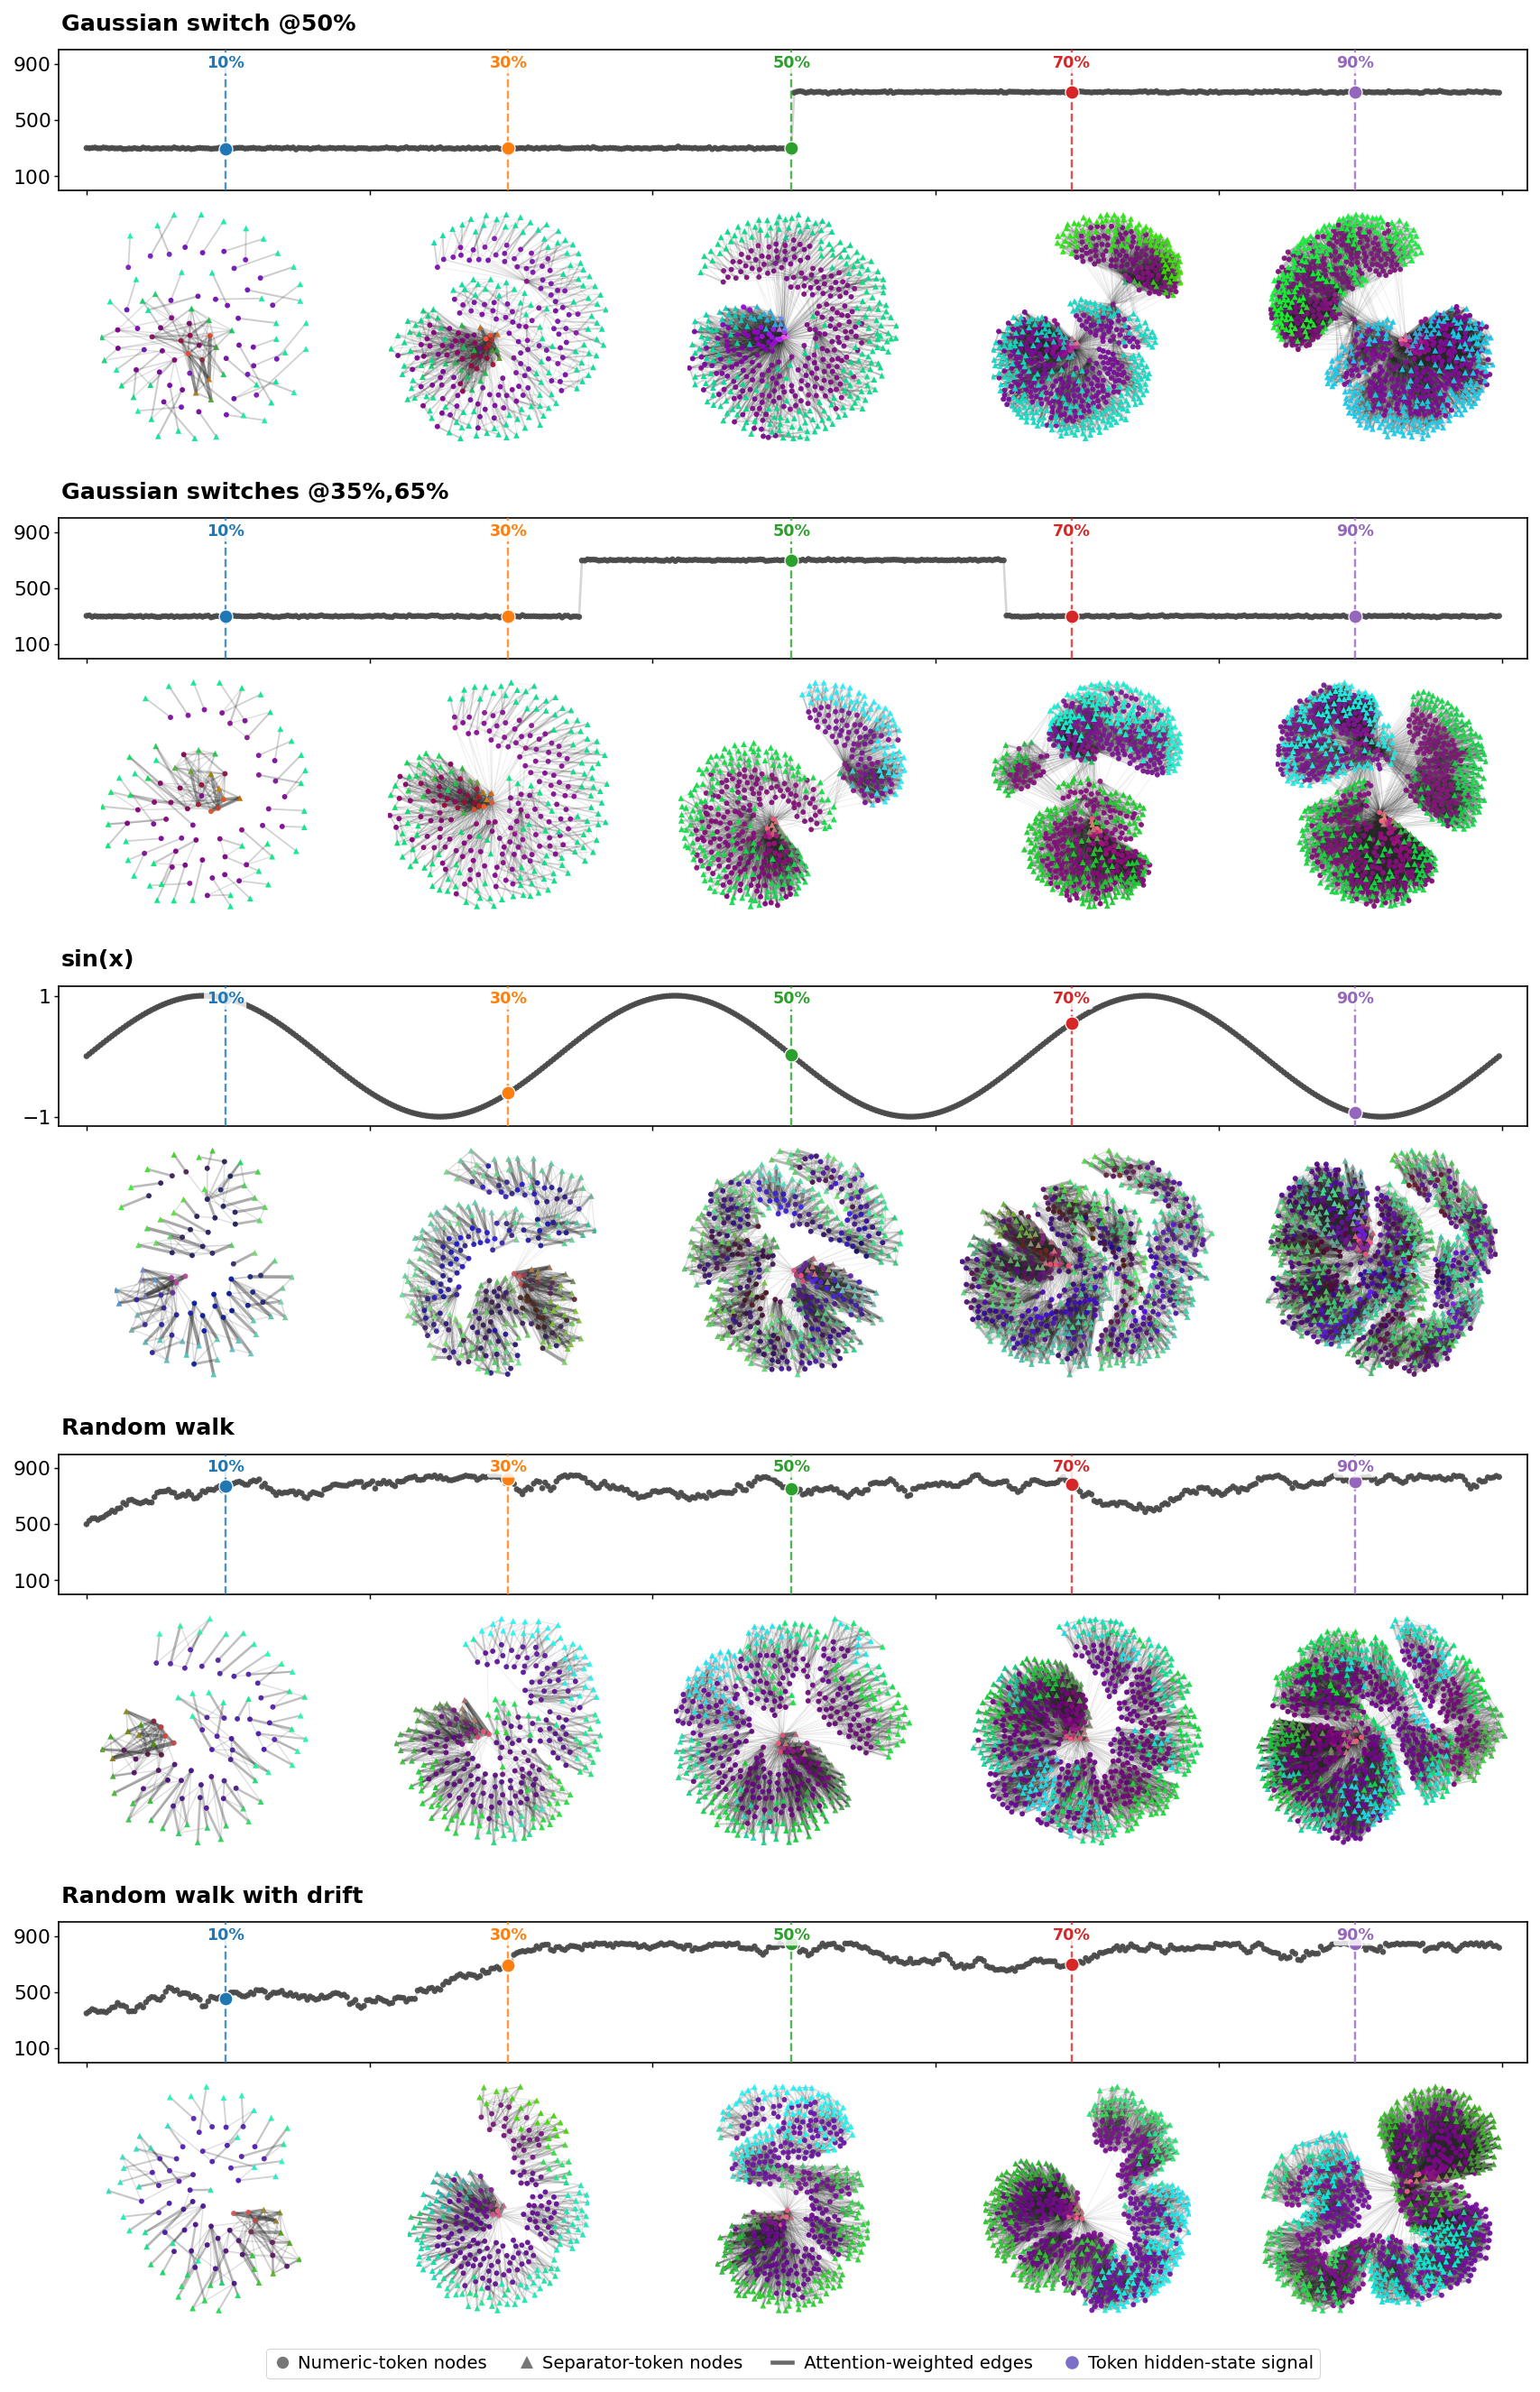

In [6]:
combined_view_fig = plot_combined_context_trajectory_and_attention_graphs(save=True, show=True)